# Fake News Detection on WELFake: Classical ML vs. BiLSTM vs. DistilBERT

**Dataset:** WELFake (Word Embedding over Linguistic Features for Fake News Detection)

**Kaggle source:** https://www.kaggle.com/datasets/saurabhshahane/fake-news-classification

This notebook covers:
1. Loading the dataset
2. Exploratory Data Analysis (EDA) - basic + advanced (word clouds, n-grams, stylistic features, correlation analysis)
3. Text preprocessing (cleaning, feature engineering, TF-IDF vectorization)
4. Stratified train/test split and export of artifacts for modeling
5. Model training & comparison: Logistic Regression, Naive Bayes, Linear SVM, Decision Tree, Random Forest, XGBoost, BiLSTM and fine-tuned DistilBERT


In [ ]:
import numpy as np
import pandas as pd
import re
import string

import matplotlib.pyplot as plt
import seaborn as sns

import nltk
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

In [ ]:
# Extra libraries for the advanced EDA
!pip install wordcloud -q

from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
import pickle


# Load Dataset

The dataset is loaded directly from Kaggle (using the Kaggle API).


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("saurabhshahane/fake-news-classification")

print("Path to dataset files:", path)

# list the files it downloaded
import os
print(os.listdir(path))

Path to dataset files: /kaggle/input/fake-news-classification
['WELFake_Dataset.csv']


In [ ]:
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
df = pd.read_csv(os.path.join(path, csv_files[0]))
df.head()

,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


# 1. Exploratory Data Analysis (EDA)

**WELFake Dataset Columns:**

* **Unnamed: 0 / id:** Row index / serial number.
* **title:** Headline of the news article.
* **text:** Full body text of the news article.
* **label [Target column]:**

        0 = Fake news
        1 = Real news

> ⚠️ **Label audit (added after the experiments were run).** The Kaggle page documents the labels as `0 = fake, 1 = real`, but the data shows the reverse:
>
> | Label | Articles | Contain the `(Reuters)` wire tag | Contain `Featured image` (a common fake-site marker) |
> |---|---:|---:|---:|
> | 0 | 35,028 | **60.7%** | 0.0% |
> | 1 | 37,106 | 0.0% | **20.0%** |
>
> The Logistic Regression coefficients in §3.5.6 agree: `reuters` is the strongest label-0 term. So **label 0 = Real and label 1 = Fake**. This changes nothing about accuracy, F1 or ROC-AUC, and the precision and recall below are therefore for the *Fake* class. However, the "Fake"/"Real" captions on the EDA plots and confusion matrices in this run are swapped and should be read the other way around.


In [ ]:
print(df.shape)
df.head(10)

(72134, 4)


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1
5,5,About Time! Christian Group Sues Amazon and SP...,All we can say on this one is it s about time ...,1
6,6,DR BEN CARSON TARGETED BY THE IRS: “I never ha...,DR. BEN CARSON TELLS THE STORY OF WHAT HAPPENE...,1
7,7,HOUSE INTEL CHAIR On Trump-Russia Fake Story: ...,,1
8,8,Sports Bar Owner Bans NFL Games…Will Show Only...,"The owner of the Ringling Bar, located south o...",1
9,9,Latest Pipeline Leak Underscores Dangers Of Da...,"FILE – In this Sept. 15, 2005 file photo, the ...",1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  72134 non-null  int64 
 1   title       71576 non-null  object
 2   text        72095 non-null  object
 3   label       72134 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 2.2+ MB


In [ ]:
# Drop unnamed index column if present
unnamed_cols = [c for c in df.columns if 'Unnamed' in c]
df = df.drop(columns=unnamed_cols, errors='ignore')
df.columns

Index(['title', 'text', 'label'], dtype='object')

In [ ]:
# Basic statistics
df.describe(include='all')

,title,text,label
count,71576,72095,72134.000000
unique,62347,62718,NaN
top,Factbox: Trump fills top jobs for his administ...,,NaN
freq,14,738,NaN
mean,NaN,NaN,0.514404
std,NaN,NaN,0.499796
min,NaN,NaN,0.000000
25%,NaN,NaN,0.000000
50%,NaN,NaN,1.000000
75%,NaN,NaN,1.000000


In [ ]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())
print("\nPercentage missing:")
print((df.isnull().sum() / len(df) * 100).round(2))

Missing values per column:
title    558
text      39
label      0
dtype: int64

Percentage missing:
title    0.77
text     0.05
label    0.00
dtype: float64


In [ ]:
# Check for duplicate rows
print(f"Total rows: {len(df)}")
print(f"Duplicate rows: {df.duplicated().sum()}")
if 'text' in df.columns:
    print(f"Duplicate article texts: {df['text'].duplicated().sum()}")

Total rows: 72134
Duplicate rows: 8456
Duplicate article texts: 9415


label
1    37106
0    35028
Name: count, dtype: int64
label
1    51.440375
0    48.559625
Name: proportion, dtype: float64


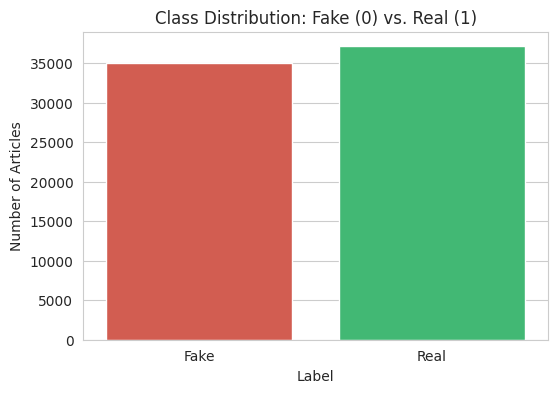

In [ ]:
# Class distribution (real vs. fake)
label_col = 'label'

print(df[label_col].value_counts())
print(df[label_col].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(x=label_col, hue=label_col, data=df, palette=['#e74c3c', '#2ecc71'], legend=False)
plt.title('Class Distribution: Fake (0) vs. Real (1)')
plt.xlabel('Label')
plt.ylabel('Number of Articles')
plt.xticks([0, 1], ['Fake', 'Real'])
plt.show()

In [ ]:
# Text length analysis (word count) for title and text
df['title_word_count'] = df['title'].fillna('').astype(str).apply(lambda x: len(x.split()))
df['text_word_count'] = df['text'].fillna('').astype(str).apply(lambda x: len(x.split()))

df[['title_word_count', 'text_word_count']].describe()

,title_word_count,text_word_count
count,72134.000000,72134.000000
mean,12.173316,540.550933
std,4.255615,625.399748
min,0.000000,0.000000
25%,9.000000,227.000000
50%,12.000000,398.000000
75%,14.000000,667.000000
max,72.000000,24234.000000


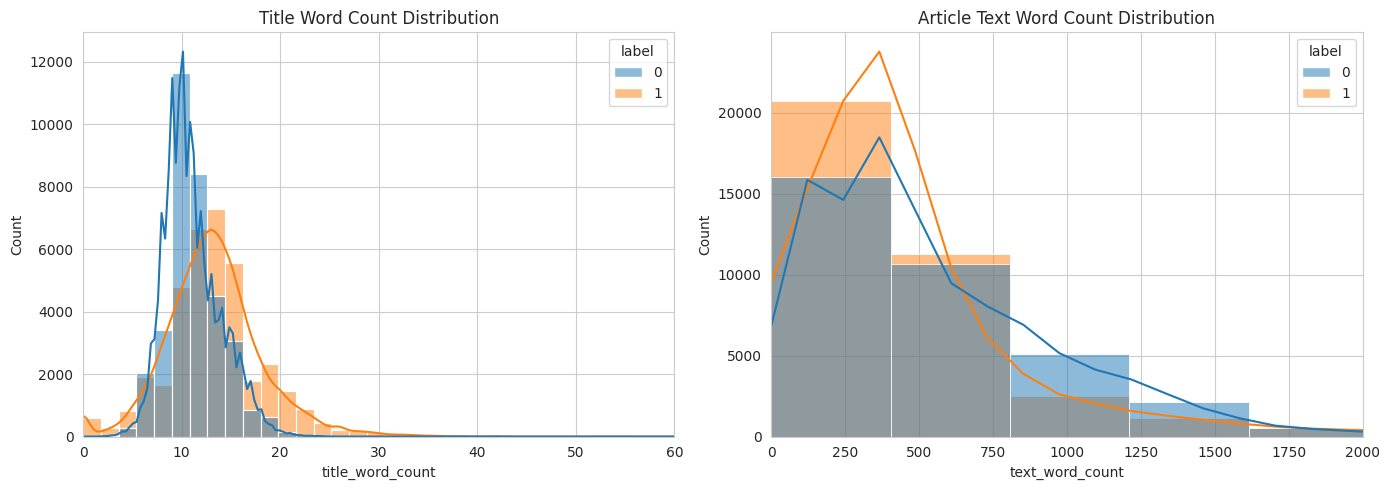

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x='title_word_count', hue=label_col, bins=40, ax=axes[0], kde=True)
axes[0].set_title('Title Word Count Distribution')
axes[0].set_xlim(0, 60)

sns.histplot(data=df, x='text_word_count', hue=label_col, bins=60, ax=axes[1], kde=True)
axes[1].set_title('Article Text Word Count Distribution')
axes[1].set_xlim(0, 2000)

plt.tight_layout()
plt.show()

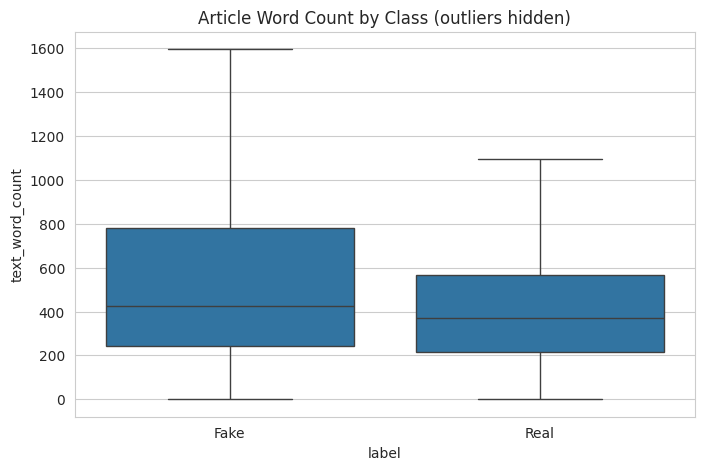

In [ ]:
# Boxplot comparison of article length by label
plt.figure(figsize=(8, 5))
sns.boxplot(x=label_col, y='text_word_count', data=df, showfliers=False)
plt.title('Article Word Count by Class (outliers hidden)')
plt.xticks([0, 1], ['Fake', 'Real'])
plt.show()

In [ ]:
# Rows with empty/very short title or text — candidates for cleaning
empty_title = (df['title'].fillna('').astype(str).str.strip() == '').sum()
empty_text = (df['text'].fillna('').astype(str).str.strip() == '').sum()
very_short_text = (df['text_word_count'] < 5).sum()

print(f"Empty titles: {empty_title}")
print(f"Empty article text: {empty_text}")
print(f"Articles with fewer than 5 words in text: {very_short_text}")

Empty titles: 558
Empty article text: 783
Articles with fewer than 5 words in text: 1002


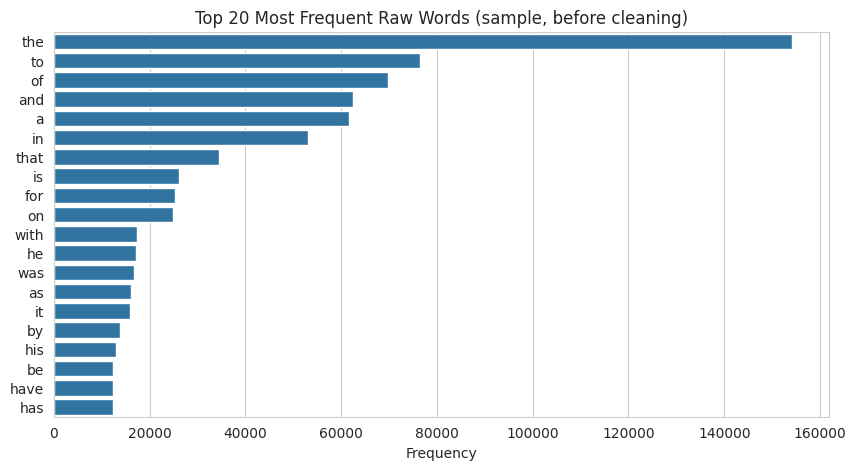

In [ ]:
# Most frequent raw words (before cleaning) for a quick sanity check
from collections import Counter

sample_texts = df['text'].fillna('').astype(str).sample(min(5000, len(df)), random_state=42)
all_words = ' '.join(sample_texts).lower().split()
most_common = Counter(all_words).most_common(20)

words, counts = zip(*most_common)
plt.figure(figsize=(10, 5))
sns.barplot(x=list(counts), y=list(words))
plt.title('Top 20 Most Frequent Raw Words (sample, before cleaning)')
plt.xlabel('Frequency')
plt.show()

## 1.1 Advanced EDA

The initial EDA above covered shape, missing values, duplicates, class balance and basic word-count statistics. This section extends the analysis with word clouds, n-gram frequency comparisons, stylistic (writing-style) features, and a correlation check between numeric features and the target label - completing the EDA required for this update.


### Word Clouds - Fake vs. Real News


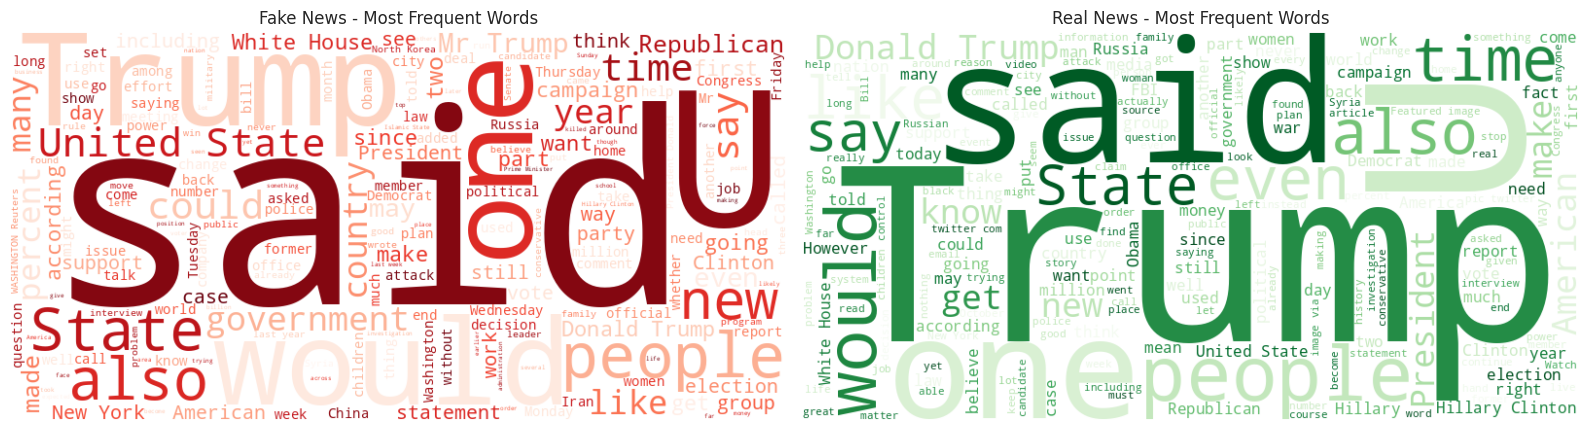

In [ ]:
# Word clouds give a quick qualitative sense of vocabulary differences between classes
fake_text = ' '.join(df.loc[df[label_col] == 0, 'text'].fillna('').astype(str).sample(
    min(5000, (df[label_col] == 0).sum()), random_state=42))
real_text = ' '.join(df.loc[df[label_col] == 1, 'text'].fillna('').astype(str).sample(
    min(5000, (df[label_col] == 1).sum()), random_state=42))

wc_fake = WordCloud(width=800, height=400, background_color='white',
                     stopwords=set(stopwords.words('english')), colormap='Reds').generate(fake_text)
wc_real = WordCloud(width=800, height=400, background_color='white',
                     stopwords=set(stopwords.words('english')), colormap='Greens').generate(real_text)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(wc_fake, interpolation='bilinear')
axes[0].set_title('Fake News - Most Frequent Words')
axes[0].axis('off')
axes[1].imshow(wc_real, interpolation='bilinear')
axes[1].set_title('Real News - Most Frequent Words')
axes[1].axis('off')
plt.tight_layout()
plt.show()


### Top Bigrams - Fake vs. Real News


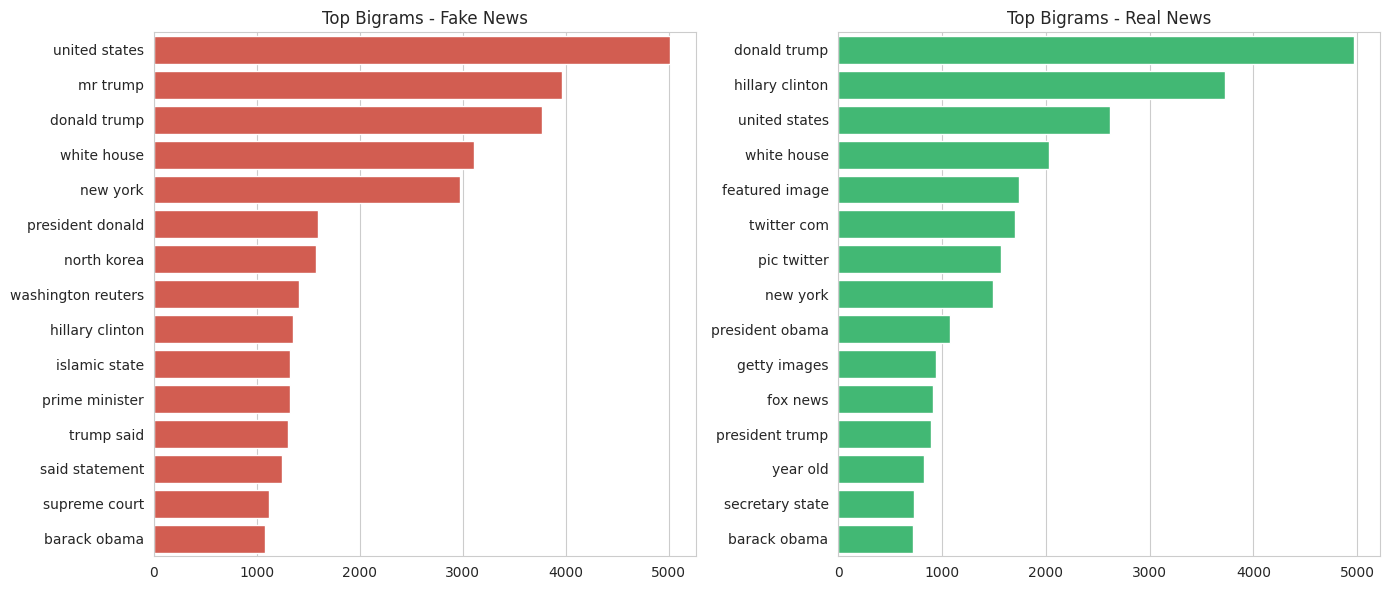

In [ ]:
# Compare the most common two-word phrases used in fake vs. real articles
def top_ngrams(text_series, ngram_range=(2, 2), top_n=15):
    vec = CountVectorizer(stop_words='english', ngram_range=ngram_range, max_features=2000)
    bow = vec.fit_transform(text_series.astype(str))
    freqs = bow.sum(axis=0).A1
    vocab = vec.get_feature_names_out()
    pairs = sorted(zip(vocab, freqs), key=lambda x: x[1], reverse=True)[:top_n]
    return pairs

fake_sample = df.loc[df[label_col] == 0, 'text'].fillna('').astype(str).sample(min(8000, (df[label_col] == 0).sum()), random_state=42)
real_sample = df.loc[df[label_col] == 1, 'text'].fillna('').astype(str).sample(min(8000, (df[label_col] == 1).sum()), random_state=42)

fake_bigrams = top_ngrams(fake_sample)
real_bigrams = top_ngrams(real_sample)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=[c for _, c in fake_bigrams], y=[w for w, _ in fake_bigrams], ax=axes[0], color='#e74c3c')
axes[0].set_title('Top Bigrams - Fake News')
sns.barplot(x=[c for _, c in real_bigrams], y=[w for w, _ in real_bigrams], ax=axes[1], color='#2ecc71')
axes[1].set_title('Top Bigrams - Real News')
plt.tight_layout()
plt.show()


### Stylistic / Writing-Style Features

Fake news articles often differ from real news in surface-level writing style (e.g. more exclamation marks, more ALL-CAPS words). These features are useful both for EDA and, later, as extra model inputs.


In [ ]:
# Compute simple stylistic features on the raw text
def exclamation_count(t):
    return str(t).count('!')

def question_count(t):
    return str(t).count('?')

def caps_word_ratio(t):
    words = str(t).split()
    if len(words) == 0:
        return 0.0
    caps = [w for w in words if w.isupper() and len(w) > 1]
    return len(caps) / len(words)

def avg_word_length(t):
    words = str(t).split()
    if len(words) == 0:
        return 0.0
    return np.mean([len(w) for w in words])

df['exclamation_count'] = df['text'].apply(exclamation_count)
df['question_count'] = df['text'].apply(question_count)
df['caps_word_ratio'] = df['text'].apply(caps_word_ratio)
df['avg_word_length'] = df['text'].apply(avg_word_length)

style_summary = df.groupby(label_col)[['exclamation_count', 'question_count',
                                        'caps_word_ratio', 'avg_word_length']].mean()
style_summary.index = ['Fake', 'Real']
style_summary


,exclamation_count,question_count,caps_word_ratio,avg_word_length
Fake,0.155561,0.524238,0.015293,5.094248
Real,0.769256,1.389937,0.020055,5.032124


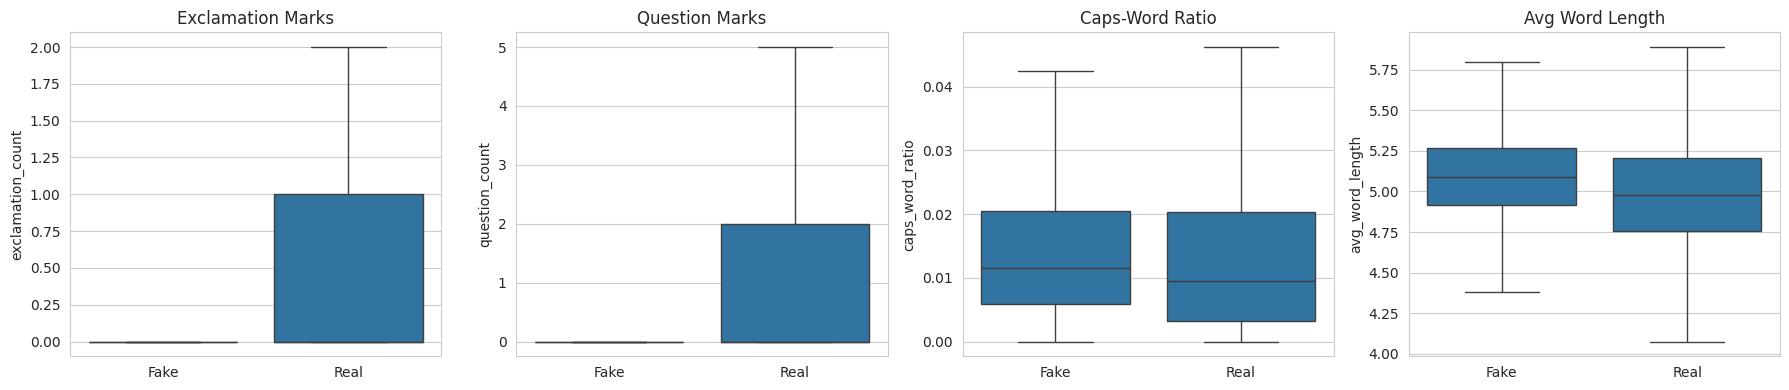

In [ ]:
# Visualize stylistic feature differences between classes
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
features = ['exclamation_count', 'question_count', 'caps_word_ratio', 'avg_word_length']
titles = ['Exclamation Marks', 'Question Marks', 'Caps-Word Ratio', 'Avg Word Length']
for ax, feat, title in zip(axes, features, titles):
    sns.boxplot(x=label_col, y=feat, data=df, ax=ax, showfliers=False)
    ax.set_xticklabels(['Fake', 'Real'])
    ax.set_title(title)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()


### Correlation Between Numeric Features and Label


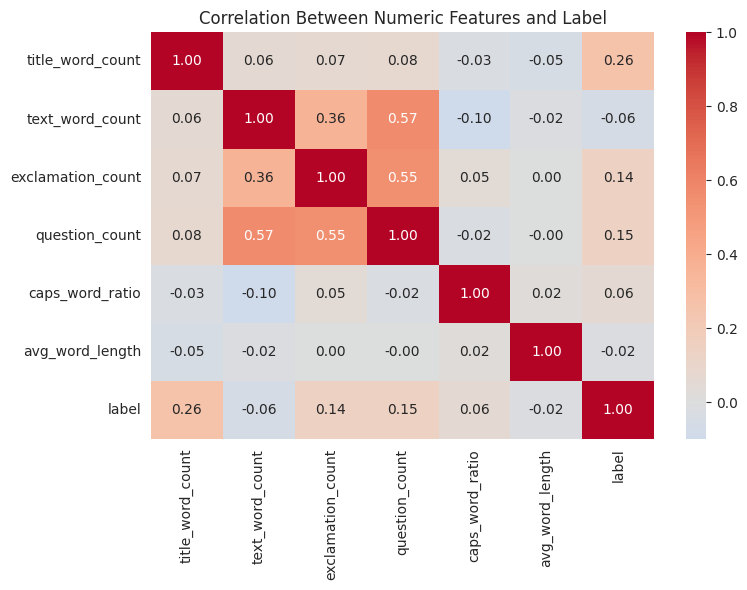

In [ ]:
# Correlation heatmap of numeric/stylistic features with the target label
numeric_cols = ['title_word_count', 'text_word_count', 'exclamation_count',
                'question_count', 'caps_word_ratio', 'avg_word_length', label_col]
corr = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Between Numeric Features and Label')
plt.tight_layout()
plt.show()


# 2. Preprocessing (Completed)

This section performs full text cleaning, engineers additional numeric features, builds a stratified train/test split, and produces TF-IDF features ready for baseline modeling.


In [ ]:
# Drop rows with missing title/text/label, then reset index
df_clean = df.dropna(subset=['title', 'text', label_col]).reset_index(drop=True)

# Drop exact duplicate articles
df_clean = df_clean.drop_duplicates(subset=['text']).reset_index(drop=True)

# Drop rows where text is essentially empty
df_clean = df_clean[df_clean['text'].astype(str).str.strip().str.len() > 0].reset_index(drop=True)

print(f"Original rows: {len(df)}  ->  After cleaning: {len(df_clean)}")

Original rows: 72134  ->  After cleaning: 62197


In [ ]:
# Combine title + text into a single field for modeling
df_clean['content'] = df_clean['title'].astype(str) + ' ' + df_clean['text'].astype(str)

In [ ]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    """Lowercase, remove URLs/HTML/punctuation/numbers, tokenize,
    remove stopwords, and lemmatize."""
    text = str(text).lower()

    # remove URLs
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    # remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)
    # remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    # remove digits
    text = re.sub(r'\d+', ' ', text)
    # collapse extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    # tokenize
    tokens = word_tokenize(text)

    # remove stopwords and short tokens, then lemmatize
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words and len(t) > 2]

    return ' '.join(tokens)

In [ ]:
# Apply cleaning (on a sample first to sanity-check speed/output before running on the full set)
sample = df_clean.sample(3, random_state=1)
for i, row in sample.iterrows():
    print('RAW:  ', row['content'][:200])
    print('CLEAN:', clean_text(row['content'])[:200])
    print('-' * 80)

RAW:    Democrats Across The Country Are Figuring Out Ways To FORCE Trump To Release His Tax Returns Every major party presidential candidate in the last 40 years has released his or her tax returns, except 
CLEAN: democrat across country figuring way force trump release tax return every major party presidential candidate last year released tax return except two one gerald ford donald trump trump completely embr
--------------------------------------------------------------------------------
RAW:    Newt Gingrich: Somebody Is Going To Jail Over Russia Probe But It Won’t Be Trump (VIDEO) Former Speaker Newt Gingrich is convinced that  somebody  is most likely going to wind up in jail when the inv
CLEAN: newt gingrich somebody going jail russia probe trump video former speaker newt gingrich convinced somebody likely going wind jail investigation russia interference election done think donald trump one
--------------------------------------------------------------------------------
RAW:  

In [ ]:
# Apply cleaning to the full dataset (may take a few minutes on ~70K rows)
df_clean['clean_content'] = df_clean['content'].apply(clean_text)
df_clean[['title', 'label', 'clean_content']].head(10)

,title,label,clean_content
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,1,law enforcement high alert following threat co...
1,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,1,unbelievable obama attorney general say charlo...
2,"Bobby Jindal, raised Hindu, uses story of Chri...",0,bobby jindal raised hindu us story christian c...
3,SATAN 2: Russia unvelis an image of its terrif...,1,satan russia unvelis image terrifying new supe...
4,About Time! Christian Group Sues Amazon and SP...,1,time christian group sue amazon splc designati...
5,DR BEN CARSON TARGETED BY THE IRS: “I never ha...,1,ben carson targeted irs never audit spoke nati...
6,Sports Bar Owner Bans NFL Games…Will Show Only...,1,sport bar owner ban nfl games…will show true a...
7,Latest Pipeline Leak Underscores Dangers Of Da...,1,latest pipeline leak underscore danger dakota ...
8,GOP Senator Just Smacked Down The Most Puncha...,1,gop senator smacked punchable altright nazi in...
9,"May Brexit offer would hurt, cost EU citizens ...",0,may brexit offer would hurt cost citizen parli...


### Most Frequent Words After Cleaning - Fake vs. Real


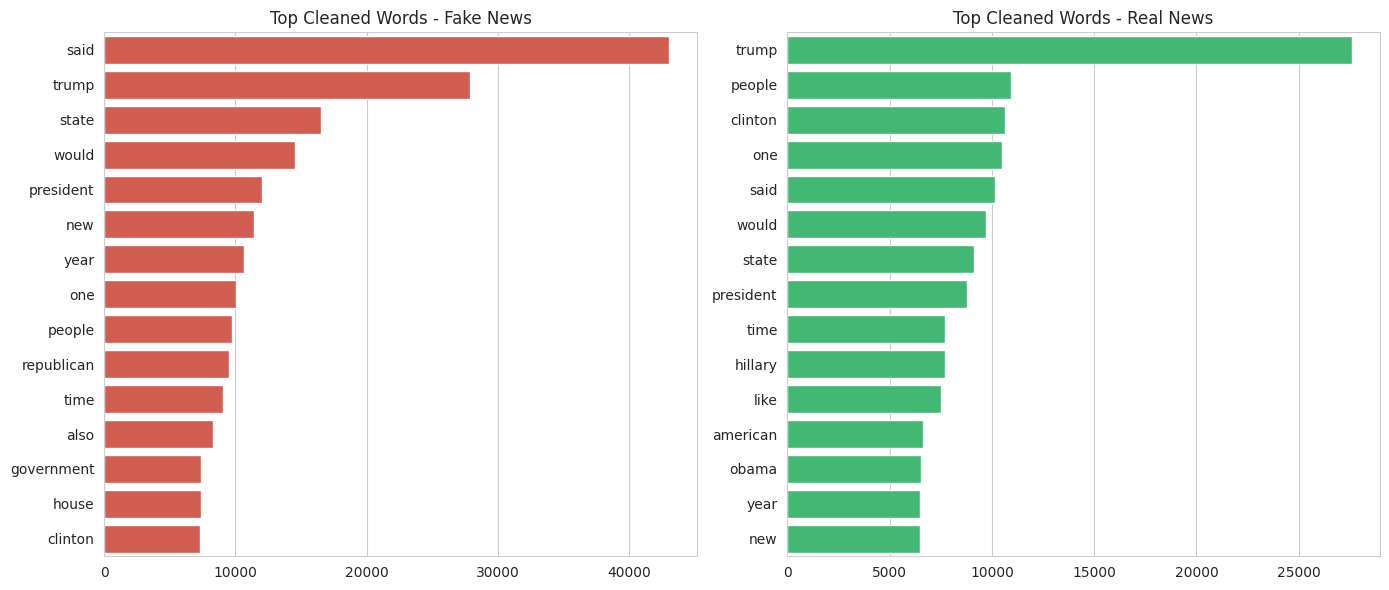

In [ ]:
# Sanity-check the cleaning step by comparing top cleaned words per class
fake_clean = df_clean.loc[df_clean[label_col] == 0, 'clean_content']
real_clean = df_clean.loc[df_clean[label_col] == 1, 'clean_content']

fake_words = Counter(' '.join(fake_clean.sample(min(8000, len(fake_clean)), random_state=42)).split()).most_common(15)
real_words = Counter(' '.join(real_clean.sample(min(8000, len(real_clean)), random_state=42)).split()).most_common(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=[c for _, c in fake_words], y=[w for w, _ in fake_words], ax=axes[0], color='#e74c3c')
axes[0].set_title('Top Cleaned Words - Fake News')
sns.barplot(x=[c for _, c in real_words], y=[w for w, _ in real_words], ax=axes[1], color='#2ecc71')
axes[1].set_title('Top Cleaned Words - Real News')
plt.tight_layout()
plt.show()


In [ ]:
# Recompute word count on cleaned text and drop rows that became empty after cleaning
df_clean['clean_word_count'] = df_clean['clean_content'].apply(lambda x: len(x.split()))
df_clean = df_clean[df_clean['clean_word_count'] > 0].reset_index(drop=True)

print(f"Final dataset size after preprocessing: {len(df_clean)}")
df_clean['clean_word_count'].describe()

Final dataset size after preprocessing: 62192


,clean_word_count
count,62192.000000
mean,310.727746
std,324.292142
min,2.000000
25%,147.000000
50%,236.000000
75%,386.000000
max,16312.000000


In [ ]:
# Confirm class balance is preserved after cleaning
print(df_clean[label_col].value_counts())
print(df_clean[label_col].value_counts(normalize=True) * 100)

label
0    34620
1    27572
Name: count, dtype: int64
label
0    55.666324
1    44.333676
Name: proportion, dtype: float64


In [ ]:
# Train / test split (stratified on label to preserve class balance)
X = df_clean['clean_content']
y = df_clean[label_col]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print(f"Train size: {len(X_train)}   Test size: {len(X_test)}")
print('Train label distribution:\n', y_train.value_counts(normalize=True))
print('Test label distribution:\n', y_test.value_counts(normalize=True))

Train size: 49753   Test size: 12439
Train label distribution:
 label
0    0.55667
1    0.44333
Name: proportion, dtype: float64
Test label distribution:
 label
0    0.556636
1    0.443364
Name: proportion, dtype: float64


### Additional Numeric Features (for models that combine text + metadata)


In [ ]:
# Carry the stylistic features computed earlier over to df_clean, aligned by index
style_cols = ['exclamation_count', 'question_count', 'caps_word_ratio', 'avg_word_length']
df_clean['exclamation_count'] = df_clean['text'].apply(exclamation_count)
df_clean['question_count'] = df_clean['text'].apply(question_count)
df_clean['caps_word_ratio'] = df_clean['text'].apply(caps_word_ratio)
df_clean['avg_word_length'] = df_clean['text'].apply(avg_word_length)

df_clean[style_cols + ['clean_word_count']].describe()


,exclamation_count,question_count,caps_word_ratio,avg_word_length,clean_word_count
count,62192.000000,62192.000000,62192.000000,62192.000000,62192.000000
mean,0.441343,0.931406,0.016960,5.090690,310.727746
std,2.133981,2.896585,0.033989,1.214000,324.292142
min,0.000000,0.000000,0.000000,2.250000,2.000000
25%,0.000000,0.000000,0.004950,4.845977,147.000000
50%,0.000000,0.000000,0.010638,5.043478,236.000000
75%,0.000000,1.000000,0.020147,5.242287,386.000000
max,213.000000,159.000000,1.000000,73.548387,16312.000000


### TF-IDF Vectorization

TF-IDF features are fit on the training split only (to avoid data leakage) and then used to transform both the train and test splits. These sparse matrices, together with `X_train`/`X_test` raw cleaned text, feed directly into the baseline models.


In [ ]:
print("\nVectorizing text...")
tfidf = TfidfVectorizer(
    stop_words='english',
    max_df=0.8,
    min_df=5,
    ngram_range=(1, 2),
    max_features=60000,
    sublinear_tf=True  # log-scale term frequency (1 + log(tf)); usually helps linear models on text
)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Aliases so downstream cells that historically used `vectorizer`/`X_train_vec` keep working
vectorizer = tfidf
X_train_vec = X_train_tfidf
X_test_vec = X_test_tfidf

print(f'TF-IDF train matrix shape: {X_train_tfidf.shape}')
print(f'TF-IDF test matrix shape:  {X_test_tfidf.shape}')


Vectorizing text...
TF-IDF train matrix shape: (49753, 60000)
TF-IDF test matrix shape:  (12439, 60000)


In [ ]:
# Peek at the highest-weighted terms overall
feature_names = np.array(tfidf.get_feature_names_out())
avg_tfidf = np.asarray(X_train_tfidf.mean(axis=0)).ravel()
top_idx = avg_tfidf.argsort()[::-1][:20]
pd.DataFrame({'term': feature_names[top_idx], 'avg_tfidf': avg_tfidf[top_idx]})

,term,avg_tfidf
0,trump,0.023860
1,said,0.022762
2,state,0.015511
3,president,0.015345
4,people,0.014010
5,new,0.013007
6,year,0.012689
7,time,0.012302
8,republican,0.012273
9,say,0.011556


In [ ]:
# Save the fitted vectorizer and TF-IDF matrices for downstream modeling notebooks
with open('tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(tfidf, f)

from scipy import sparse
sparse.save_npz('X_train_tfidf.npz', X_train_tfidf)
sparse.save_npz('X_test_tfidf.npz', X_test_tfidf)
y_train.to_csv('y_train.csv', index=False)
y_test.to_csv('y_test.csv', index=False)

print('Saved: tfidf_vectorizer.pkl, X_train_tfidf.npz, X_test_tfidf.npz, y_train.csv, y_test.csv')

Saved: tfidf_vectorizer.pkl, X_train_tfidf.npz, X_test_tfidf.npz, y_train.csv, y_test.csv


In [ ]:
# Save the cleaned dataset (including engineered features) for downstream notebooks
output_cols = ['title', 'text', 'clean_content', 'title_word_count', 'text_word_count',
               'clean_word_count', 'exclamation_count', 'question_count',
               'caps_word_ratio', 'avg_word_length', label_col]
df_clean[output_cols].to_csv('welfake_cleaned.csv', index=False)
print('Saved cleaned dataset to welfake_cleaned.csv')

Saved cleaned dataset to welfake_cleaned.csv


# 3. Model Implementation

This section trains and compares four families of models on the TF-IDF features (and, for two models, the raw cleaned text) produced above:

1. **Baseline linear/probabilistic models** — Logistic Regression, Multinomial Naive Bayes, Linear SVM
2. **Tree-based / boosting models** — Decision Tree, Random Forest, XGBoost
3. **Deep learning** — a Bidirectional LSTM over learned word embeddings
4. **Transformer fine-tuning** — DistilBERT

All models are evaluated on the same stratified train/test split so results are directly comparable.

## 3.1 Baseline Models: Logistic Regression, Naive Bayes, Linear SVM

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

### 3.1.1 Hyperparameter Tuning

Rather than using default hyperparameters, a small grid search (3-fold CV, scored on F1) tunes the regularization strength `C` for Logistic Regression and Linear SVM. This alone typically improves accuracy by a percent or more over untuned defaults, at a small, fixed compute cost since the grid is small and TF-IDF vectors are sparse.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Small, cheap grids -- just enough to move C off of sklearn's default of 1.0
lr_grid = GridSearchCV(
    LogisticRegression(max_iter=1000, class_weight='balanced'),
    param_grid={'C': [0.1, 1, 3, 10]},
    scoring='f1', cv=3, n_jobs=-1,
)
lr_grid.fit(X_train_vec, y_train)
print('Best Logistic Regression params:', lr_grid.best_params_, ' CV F1:', round(lr_grid.best_score_, 4))

svm_grid = GridSearchCV(
    LinearSVC(class_weight='balanced'),
    param_grid={'C': [0.1, 0.5, 1, 3]},
    scoring='f1', cv=3, n_jobs=-1,
)
svm_grid.fit(X_train_vec, y_train)
print('Best Linear SVM params:        ', svm_grid.best_params_, ' CV F1:', round(svm_grid.best_score_, 4))

Best Logistic Regression params: {'C': 10}  CV F1: 0.9584
Best Linear SVM params:         {'C': 1}  CV F1: 0.9603


### 3.1.2 Train & Evaluate Baseline Models

In [ ]:
models = {
    "Logistic Regression": lr_grid.best_estimator_,
    "Naive Bayes": MultinomialNB(),
    "SVM": svm_grid.best_estimator_,
}

In [ ]:
from sklearn.metrics import accuracy_score, classification_report
import time

results = {}
train_times = {}
print("\nTraining Models...\n")

for name, model in models.items():
    print(f"Training: {name}")

    start = time.time()
    model.fit(X_train_vec, y_train)
    train_times[name] = time.time() - start

    preds = model.predict(X_test_vec)
    acc = accuracy_score(y_test, preds)
    results[name] = acc

    print(f"Accuracy: {acc:.4f}")
    print(f"Training time: {train_times[name]:.2f}s")
    print(classification_report(y_test, preds))
    print('-' * 70)


Training Models...

Training: Logistic Regression
Accuracy: 0.9678
Training time: 1.83s
              precision    recall  f1-score   support

           0       0.97      0.97      0.97      6924
           1       0.96      0.97      0.96      5515

    accuracy                           0.97     12439
   macro avg       0.97      0.97      0.97     12439
weighted avg       0.97      0.97      0.97     12439

----------------------------------------------------------------------
Training: Naive Bayes
Accuracy: 0.8838
Training time: 0.11s
              precision    recall  f1-score   support

           0       0.91      0.88      0.89      6924
           1       0.86      0.89      0.87      5515

    accuracy                           0.88     12439
   macro avg       0.88      0.88      0.88     12439
weighted avg       0.88      0.88      0.88     12439

----------------------------------------------------------------------
Training: SVM
Accuracy: 0.9694
Training time: 1.15s
   

### 3.1.3 Best Baseline Model

In [ ]:
best_model_name = max(results, key=results.get)
best_accuracy = results[best_model_name]
print("\nBest Model:", best_model_name)
print("Best Accuracy:", best_accuracy)
best_model = models[best_model_name]


Best Model: SVM
Best Accuracy: 0.9693705281775062


## 3.2 Tree-Based & Boosting Models: Decision Tree, Random Forest, XGBoost

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              classification_report, roc_curve)

!pip install -q xgboost
from xgboost import XGBClassifier

In [ ]:
# Extend the existing `models` dict (Logistic Regression, Naive Bayes, SVM)
models["Decision Tree"] = DecisionTreeClassifier(max_depth=50, random_state=42)
models["Random Forest"] = RandomForestClassifier(
    n_estimators=200, max_depth=None, min_samples_leaf=1,
    n_jobs=-1, random_state=42
)
models["XGBoost"] = XGBClassifier(
    n_estimators=250, max_depth=6, learning_rate=0.1,
    subsample=0.9, colsample_bytree=0.9,
    eval_metric='logloss', n_jobs=-1, random_state=42
)

# Train and evaluate the newly added models
new_model_names = ["Decision Tree", "Random Forest", "XGBoost"]

for name in new_model_names:
    print(f"Training: {name}")
    model = models[name]
    start = time.time()
    model.fit(X_train_vec, y_train)
    train_times[name] = time.time() - start
    preds = model.predict(X_test_vec)
    acc = accuracy_score(y_test, preds)
    results[name] = acc
    print(f"Accuracy: {acc:.4f}")
    print(f"Training time: {train_times[name]:.2f}s")
    print(classification_report(y_test, preds))
    print('-' * 70)

Training: Decision Tree
Accuracy: 0.9290
Training time: 160.96s
              precision    recall  f1-score   support

           0       0.94      0.94      0.94      6924
           1       0.92      0.92      0.92      5515

    accuracy                           0.93     12439
   macro avg       0.93      0.93      0.93     12439
weighted avg       0.93      0.93      0.93     12439

----------------------------------------------------------------------
Training: Random Forest
Accuracy: 0.9395
Training time: 285.64s
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      6924
           1       0.94      0.92      0.93      5515

    accuracy                           0.94     12439
   macro avg       0.94      0.94      0.94     12439
weighted avg       0.94      0.94      0.94     12439

----------------------------------------------------------------------
Training: XGBoost
Accuracy: 0.9635
Training time: 986.20s
              prec

## 3.3 Deep Learning: Bidirectional LSTM

A word-embedding + BiLSTM model trained on padded token sequences of the cleaned text (independent of the TF-IDF features used above).

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)

MAX_VOCAB = 20000
MAX_LEN = 300
EMBED_DIM = 128

tokenizer_dl = Tokenizer(num_words=MAX_VOCAB, oov_token='<OOV>')
tokenizer_dl.fit_on_texts(X_train)

X_train_seq = tokenizer_dl.texts_to_sequences(X_train)
X_test_seq = tokenizer_dl.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='post', truncating='post')

print('Padded train shape:', X_train_pad.shape)
print('Padded test shape: ', X_test_pad.shape)

Padded train shape: (49753, 300)
Padded test shape:  (12439, 300)


### 3.3.1 Model Architecture

| Layer | Output shape | Params |
|---|---|---:|
| Embedding (20,000 × 128) | (None, 300, 128) | 2,560,000 |
| Bidirectional LSTM (64 units each way) | (None, 128) | 98,816 |
| Dropout (0.5) | (None, 128) | 0 |
| Dense (64, ReLU) | (None, 64) | 8,256 |
| Dropout (0.4) | (None, 64) | 0 |
| Dense (1, sigmoid) | (None, 1) | 65 |
| **Total** | | **2,667,137** |


In [ ]:
from tensorflow.keras.regularizers import l2

lstm_model = Sequential([
    Embedding(input_dim=MAX_VOCAB, output_dim=EMBED_DIM, input_length=MAX_LEN),
    Bidirectional(LSTM(64, return_sequences=False,
                        dropout=0.3, recurrent_dropout=0.2,
                        kernel_regularizer=l2(1e-4))),
    Dropout(0.5),
    Dense(64, activation='relu', kernel_regularizer=l2(1e-4)),
    Dropout(0.4),
    Dense(1, activation='sigmoid'),
])

lstm_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
lstm_model.build(input_shape=(None, MAX_LEN))  # build so summary() reports real shapes/params
lstm_model.summary()

### 3.3.2 Training

In [ ]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

early_stop = EarlyStopping(monitor='val_loss', patience=1, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=0, min_lr=1e-6)

start = time.time()
history = lstm_model.fit(
    X_train_pad, y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=128,
    callbacks=[early_stop, reduce_lr],
    verbose=1,
)

train_times['BiLSTM'] = time.time() - start

Epoch 1/10
350/350 ━━━━━━━━━━━━━━━━━━━━ 728s 2s/step - accuracy: 0.9198 - loss: 0.2147 - val_accuracy: 0.9572 - val_loss: 0.1256 - learning_rate: 0.0010
Epoch 2/10
350/350 ━━━━━━━━━━━━━━━━━━━━ 710s 2s/step - accuracy: 0.9714 - loss: 0.0978 - val_accuracy: 0.9596 - val_loss: 0.1240 - learning_rate: 0.0010
Epoch 3/10
350/350 ━━━━━━━━━━━━━━━━━━━━ 708s 2s/step - accuracy: 0.9832 - loss: 0.0648 - val_accuracy: 0.9596 - val_loss: 0.1450 - learning_rate: 0.0010


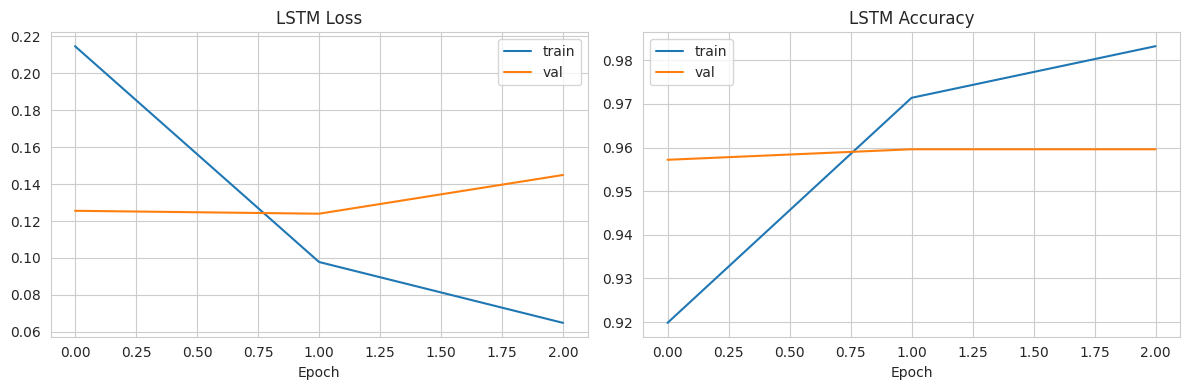

In [ ]:
# Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['loss'], label='train')
axes[0].plot(history.history['val_loss'], label='val')
axes[0].set_title('LSTM Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()

axes[1].plot(history.history['accuracy'], label='train')
axes[1].plot(history.history['val_accuracy'], label='val')
axes[1].set_title('LSTM Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout()
plt.show()

### 3.3.3 Evaluation

In [ ]:
print("Training: BiLSTM")

lstm_probs = lstm_model.predict(X_test_pad).ravel()
lstm_preds = (lstm_probs >= 0.5).astype(int)

lstm_acc = accuracy_score(y_test, lstm_preds)
results['BiLSTM'] = lstm_acc

print(f"Accuracy: {lstm_acc:.4f}")
print(f"Training time: {train_times['BiLSTM']:.2f}s")
print(classification_report(y_test, lstm_preds))
print('-' * 70)

Training: BiLSTM
389/389 ━━━━━━━━━━━━━━━━━━━━ 152s 390ms/step
Accuracy: 0.9584
Training time: 2145.66s
              precision    recall  f1-score   support

           0       0.97      0.95      0.96      6924
           1       0.94      0.97      0.95      5515

    accuracy                           0.96     12439
   macro avg       0.96      0.96      0.96     12439
weighted avg       0.96      0.96      0.96     12439

----------------------------------------------------------------------


# **3.4 Transformer fine-tuning (DistilBERT)**

Fine-tuning a pretrained DistilBERT model on the same train/test split used for the classical models and BiLSTM, so all approaches are compared on identical data.

In [ ]:
!pip install -q transformers datasets accelerate

import torch
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, default_data_collator
)
from datasets import Dataset

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)
if device.type != 'cuda':
    print('WARNING: no GPU detected — Runtime > Change runtime type > GPU')

Using device: cuda


### 3.4.1 Tokenize Datasets

In [ ]:
MODEL_NAME = 'distilbert-base-uncased'
MAX_LEN = 300

tokenizer_tf = AutoTokenizer.from_pretrained(MODEL_NAME)

train_ds = Dataset.from_dict({'text': list(X_train), 'label': list(y_train)})
test_ds = Dataset.from_dict({'text': list(X_test), 'label': list(y_test)})

def tokenize_fn(batch):
    return tokenizer_tf(batch['text'], truncation=True, padding='max_length', max_length=MAX_LEN)

train_ds = train_ds.map(tokenize_fn, batched=True)
test_ds = test_ds.map(tokenize_fn, batched=True)

train_ds = train_ds.remove_columns(['text'])
test_ds = test_ds.remove_columns(['text'])

print('Train examples:', len(train_ds), ' Test examples:', len(test_ds))

Train examples: 49753  Test examples: 12439


### 3.4.2 Build Trainer

In [ ]:
models["distilbert-base-uncased"] = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2).to(device)

training_args = TrainingArguments(
    output_dir='./distilbert_fakenews',
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy='epoch',
    save_strategy='no',
    logging_steps=100,
    fp16=torch.cuda.is_available(),
    report_to='none',
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(axis=-1)
    return {'accuracy': accuracy_score(labels, preds), 'f1': f1_score(labels, preds)}

trainer = Trainer(
    model= models[MODEL_NAME],
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=test_ds,
    data_collator=default_data_collator,
    compute_metrics=compute_metrics,
)

In [ ]:
start = time.time()
trainer.train()
train_times[MODEL_NAME] = time.time() - start

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.050268,0.062248,0.983439,0.981215
2,0.032665,0.057262,0.985851,0.984081


In [ ]:
print("Training: DistilBERT")

preds_output = trainer.predict(test_ds)
logits = preds_output.predictions
probs = torch.softmax(torch.tensor(logits), dim=-1)[:, 1].numpy()

distilbert_preds = (probs >= 0.5).astype(int)
distilbert_acc = accuracy_score(y_test, distilbert_preds)
results['DistilBERT'] = distilbert_acc

print(f"Accuracy: {distilbert_acc:.4f}")
print(f"Training time: {train_times[MODEL_NAME]:.2f}s")
print(classification_report(y_test, distilbert_preds))
print('-' * 70)

Training: DistilBERT


Accuracy: 0.9859
Training time: 880.97s
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      6924
           1       0.98      0.99      0.98      5515

    accuracy                           0.99     12439
   macro avg       0.99      0.99      0.99     12439
weighted avg       0.99      0.99      0.99     12439

----------------------------------------------------------------------


## 3.5 Model Comparison (All Models)

In [ ]:
def get_scores(name, model, X_te, y_te, proba_from=None, train_time=None):
    if proba_from is not None:
        y_score = proba_from
        y_pred = (y_score >= 0.5).astype(int)
    else:
        y_pred = model.predict(X_te)
        if hasattr(model, 'predict_proba'):
            y_score = model.predict_proba(X_te)[:, 1]
        elif hasattr(model, 'decision_function'):
            y_score = model.decision_function(X_te)
        else:
            y_score = y_pred

    return {
        'Model': name,
        'Accuracy': accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred),
        'Recall': recall_score(y_te, y_pred),
        'F1': f1_score(y_te, y_pred),
        'ROC-AUC': roc_auc_score(y_te, y_score),
        'Train Time (s)': train_time,
        'y_pred': y_pred,
        'y_score': y_score,
    }

In [ ]:
model_objects = {name: m for name, m in models.items() if name != MODEL_NAME}
model_objects['DistilBERT'] = models[MODEL_NAME]
model_objects['BiLSTM'] = lstm_model

all_scores = []
all_scores.append(get_scores('DistilBERT', None, None, y_test, proba_from=probs,
                              train_time=train_times.get(MODEL_NAME)))
all_scores.append(get_scores('BiLSTM', None, None, y_test, proba_from=lstm_probs,
                              train_time=train_times.get('BiLSTM')))
for name, model in models.items():
    if name == MODEL_NAME:
        continue
    all_scores.append(get_scores(name, model, X_test_vec, y_test,
                                  train_time=train_times.get(name)))

metrics_df = pd.DataFrame(all_scores).drop(columns=['y_pred', 'y_score'])
metrics_df = metrics_df.sort_values('F1', ascending=False).reset_index(drop=True)

results_df = metrics_df.set_index('Model').rename(columns={
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC-AUC': 'roc_auc',
    'Train Time (s)': 'train_time_s',
})

metrics_df.style.format({c: '{:.4f}' for c in ['Accuracy','Precision','Recall','F1','ROC-AUC','Train Time (s)']}).background_gradient(cmap='Greens', subset=['F1'])

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (s)
0,DistilBERT,0.9859,0.9818,0.9864,0.9841,0.9992,880.9675
1,SVM,0.9694,0.9625,0.9686,0.9656,0.9952,1.1496
2,Logistic Regression,0.9678,0.9612,0.9663,0.9637,0.9946,1.8250
3,XGBoost,0.9635,0.9516,0.9668,0.9592,0.9943,986.1955
4,BiLSTM,0.9584,0.9426,0.9650,0.9537,0.9924,2145.6628
5,Random Forest,0.9395,0.9421,0.9200,0.9309,0.9859,285.6356
6,Decision Tree,0.9290,0.9205,0.9193,0.9199,0.9020,160.9568
7,Naive Bayes,0.8838,0.8551,0.8885,0.8715,0.9514,0.1132


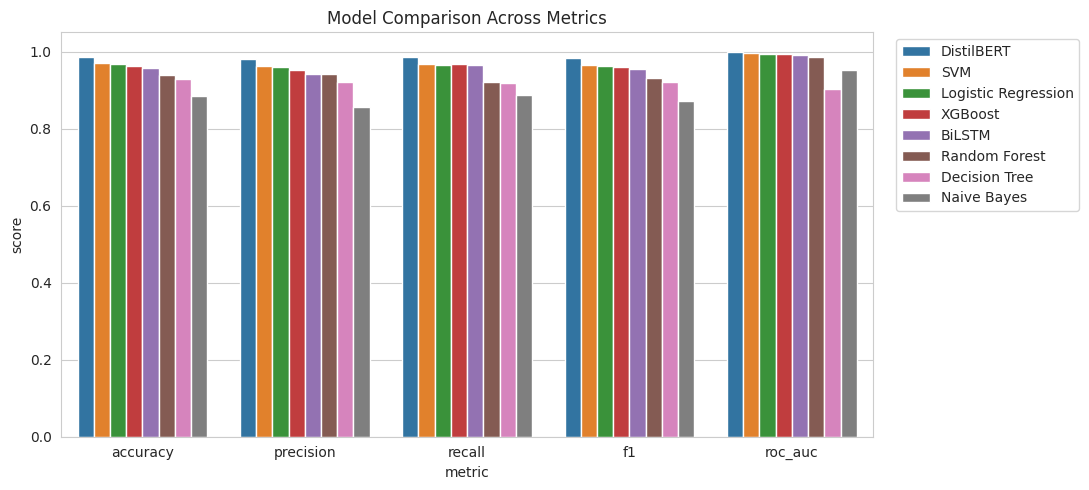

In [ ]:
# Bar chart comparing the models across the main metrics
metrics_to_plot = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
plot_df = results_df[metrics_to_plot].reset_index()
plot_df = plot_df.rename(columns={plot_df.columns[0]: 'model'})
plot_df = plot_df.melt(id_vars='model', var_name='metric', value_name='score')

plt.figure(figsize=(11, 5))
sns.barplot(data=plot_df, x='metric', y='score', hue='model')
plt.title('Model Comparison Across Metrics')
plt.ylim(0, 1.05)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

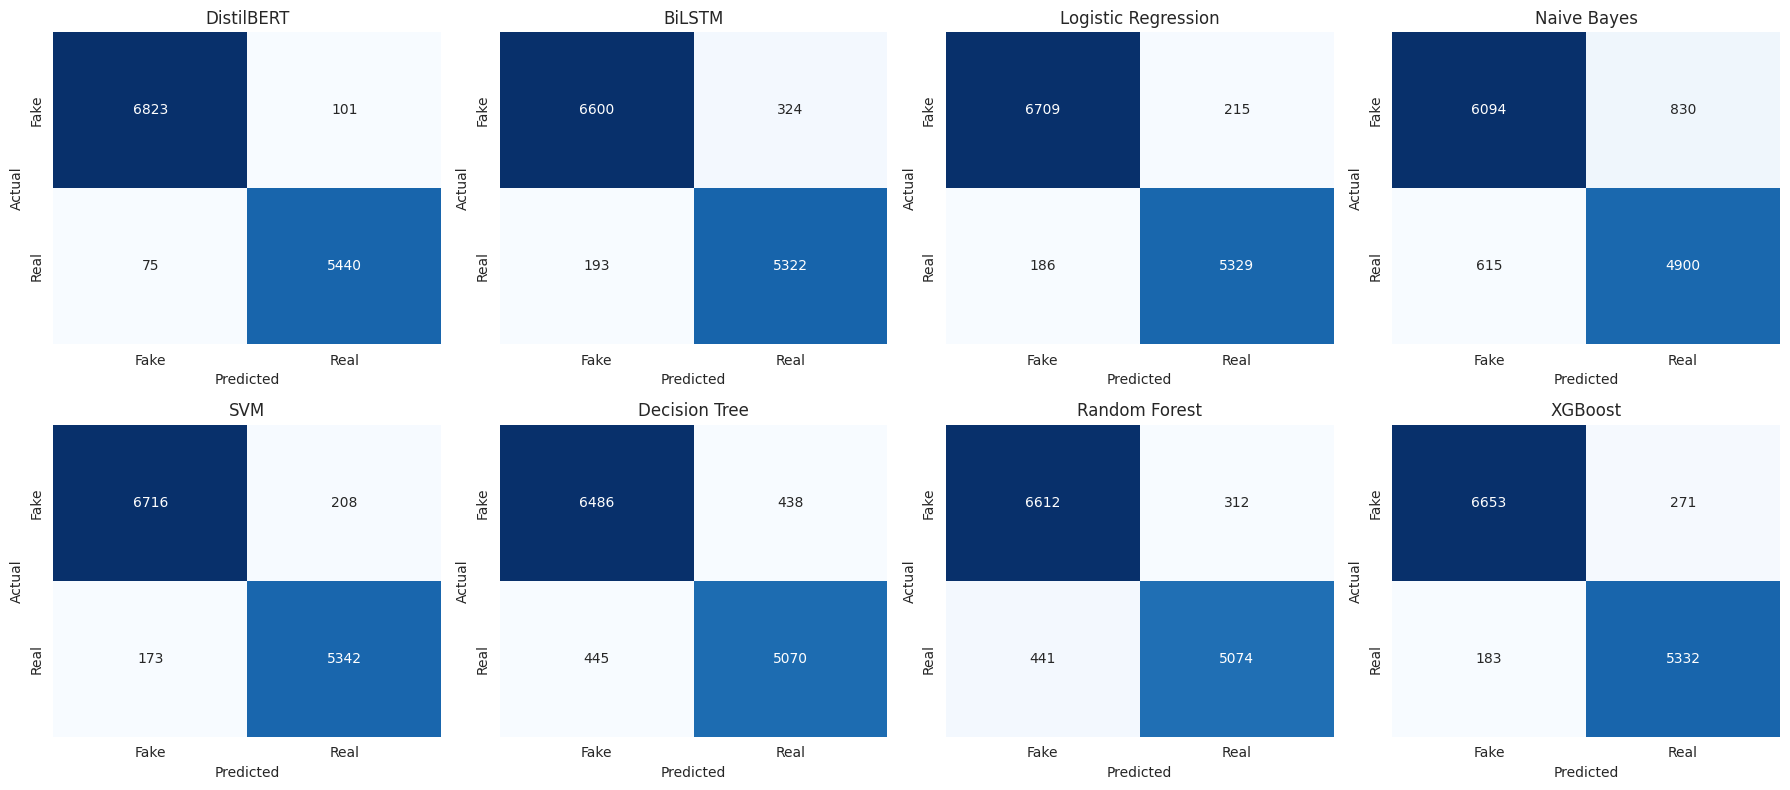

In [ ]:
# Confusion matrices for every model, in a grid
n_models = len(all_scores)
n_cols = 4
n_rows = int(np.ceil(n_models / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 4 * n_rows))
axes = axes.flatten()

for i, s in enumerate(all_scores):
    cm = confusion_matrix(y_test, s['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'], ax=axes[i])
    axes[i].set_title(s['Model'])
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

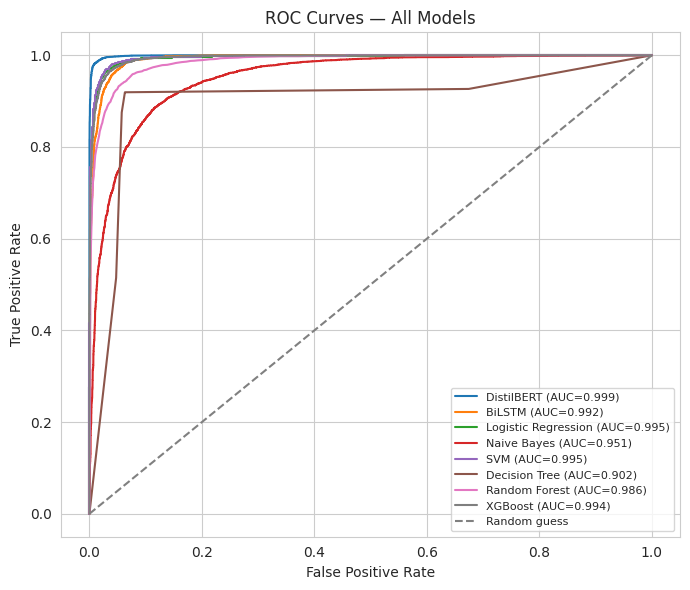

In [ ]:
# ROC curves overlaid for all models
fig, ax = plt.subplots(figsize=(7, 6))
for s in all_scores:
    fpr, tpr, _ = roc_curve(y_test, s['y_score'])
    ax.plot(fpr, tpr, label=f"{s['Model']} (AUC={s['ROC-AUC']:.3f})")

ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — All Models')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 3.5.6 Feature Importance (Logistic Regression)

As a quick interpretability check, the largest positive/negative Logistic Regression coefficients show which TF-IDF terms push predictions toward *Real* vs. *Fake*.

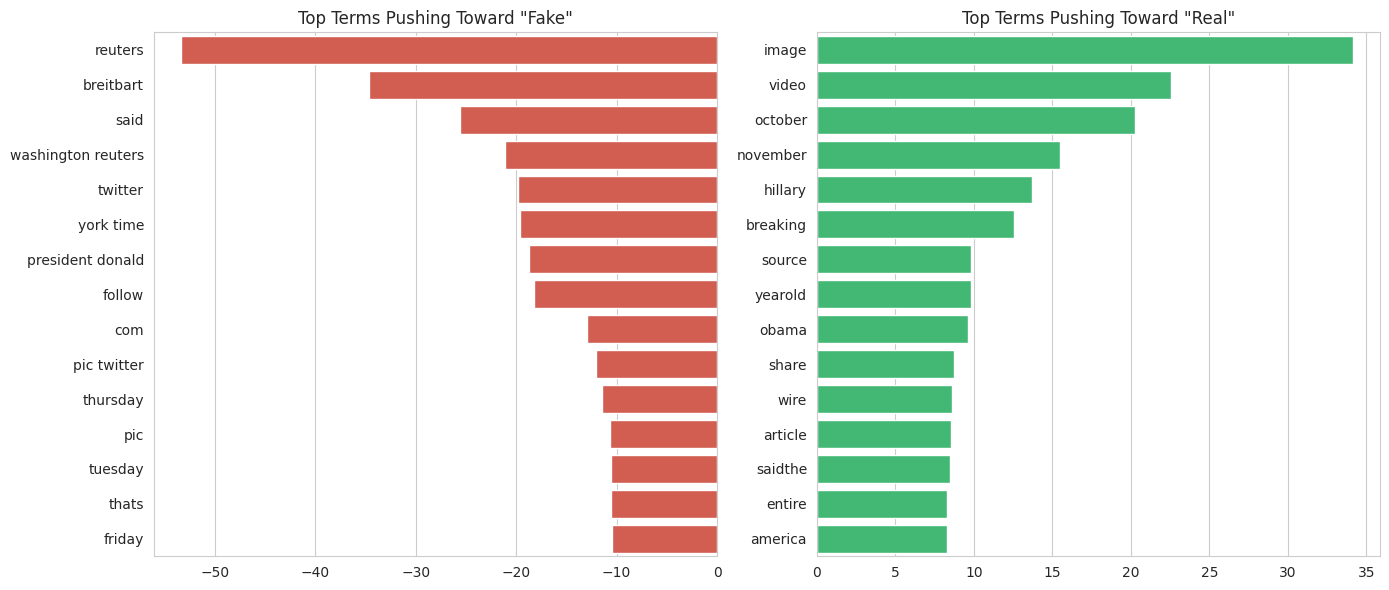

In [ ]:
lr_model = models['Logistic Regression']
feature_names = np.array(tfidf.get_feature_names_out())
coefs = lr_model.coef_[0]

top_real_idx = coefs.argsort()[::-1][:15]
top_fake_idx = coefs.argsort()[:15]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=coefs[top_fake_idx], y=feature_names[top_fake_idx], ax=axes[0], color='#e74c3c')
axes[0].set_title('Top Terms Pushing Toward "Fake"')

sns.barplot(x=coefs[top_real_idx], y=feature_names[top_real_idx], ax=axes[1], color='#2ecc71')
axes[1].set_title('Top Terms Pushing Toward "Real"')

plt.tight_layout()
plt.show()

# **Save Best Model and Results**

In [ ]:
best_model_name = results_df['f1'].idxmax()
best_model = model_objects[best_model_name]

print(f"Best model by F1-score: {best_model_name}")
print(results_df.loc[best_model_name])

results_df.to_csv('model_comparison_update3.csv')

with open('best_model_update3.pkl', 'wb') as f:
    pickle.dump(best_model, f)

print("\nSaved: model_comparison_update3.csv, best_model_update3.pkl")

Best model by F1-score: DistilBERT
accuracy          0.985851
precision         0.981772
recall            0.986401
f1                0.984081
roc_auc           0.999164
train_time_s    880.967544
Name: DistilBERT, dtype: float64

Saved: model_comparison_update3.csv, best_model_update3.pkl
